In [3]:
pip install Finesse3

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement Finesse3 (from versions: none)
ERROR: No matching distribution found for Finesse3


In [13]:
import finesse
from finesse.components import Space, Lens, Laser, Nothing
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

In [40]:
def setup_model(f1, f2, f3, f4, d1, d2, d3, d4, d5, visualise=False):
    """
    Creates a simple model of two lenses of focal lengths f1,f2 and three distances, d1, d2, d3.
    """
    M = finesse.model.Model()
    M.lambda0 = 1550e-9 # set the model's wavelength to 1550nm
    
    # first create a laser
    Laser_1550 = Laser("laser_1550", P=1, f=(300e6)/(1550e-9))
    M.add(Laser_1550)
    
    # create two lenses
    
    lens_1 = Lens("lens_1", f=f1)
    lens_2 = Lens("lens_2", f=f2)
    lens_3 = Lens("lens_3", f=f3)
    lens_4 = Lens("lens_4", f=f4)
    
    M.add([lens_1, lens_2, lens_3, lens_4])
    
    # add a target, represented by a 'Nothing' node
    target = Nothing("target")
    M.add(target)
    
    # now create the spaces between components
    s_L_l1 = Space("s_L_l1", portA=Laser_1550.p1, portB=lens_1.p1, L=d1)
    s_l1_l2 = Space("s_l1_l2", portA=lens_1.p2, portB=lens_2.p1, L=d2)
    s_l2_t = Space("s_l4_t", portA=lens_4.p2, portB=target.p1, L=d3)
    s_l2_l3 = Space("s_l2_l3", portA=lens_2.p2, portB=lens_3.p1, L=d4)
    s_l3_l4 = Space("s_l3_l4", portA=lens_3.p2, portB=lens_4.p1, L=d5)


    
    M.add([s_L_l1, s_l1_l2, s_l2_t, s_l2_l3, s_l3_l4])
    
    # check if the output looks alright
    # NB The graph just shows what is connected to what. It doesn't represent physical space.
    if visualise == True:
        print(M.component_tree())
        M.plot_graph(arrows=True, graphviz=False, layout="spiral")
    return M

In [51]:
f1=0.1
f2=0.3
f3=0.3
f4=0.1
d1=0.05
d2=f1+f2
d3=0.05
d4=256
d5=f1+f2

In [52]:
q_f810apc_1550 = finesse.gaussian.BeamParam(wavelength=1550e-9, w0=3.5e-3, z=37.20e-3)
tel_zs = np.linspace(0.3275, 0.3325, 60)

In [53]:
# Set up the model with parameters described above
M = setup_model(f1, f2, f3, f4, d1, d2, d3, d4, d5)

# Create a beam path for the simulation to follow from the first node to the last node in the model, M
nodes = M.optical_nodes
beam_path = M.path(nodes[1], nodes[-1])

# Simulate
sim_f810 = M.propagate_beam(path=beam_path, q_in=q_f810apc_1550, symbolic=True)

# Range of values for tel_zs
tel_zs_range = np.linspace(0.3957, 0.4007, 60)  # Adjust the range and steps as needed
rec_zs_range = np.linspace(d5-0.01, d5+0.02, 60)

# Function to update the plot based on slider value
def update_plot(tel_zs_value, rec_zs_value):
    M.s_l1_l2.L = tel_zs_value  # Manually set the parameter
    M.s_l3_l4.L = rec_zs_value
    sim_f810.plot("beamsize",single_sided=False)  # Directly call plot without ax argument
    #print("f810apc_1550:".upper())
    #print(sim_f810)
# Create an interactive slider
slider = FloatSlider(min=tel_zs_range.min(), max=tel_zs_range.max(), step=0.00001, value=tel_zs_range.min(), readout_format=".5f")
slider2 = FloatSlider(min=rec_zs_range.min(), max=rec_zs_range.max(), step=0.00001, value=rec_zs_range.min(), readout_format=".5f")
interact(update_plot, tel_zs_value=slider, rec_zs_value=slider2)

interactive(children=(FloatSlider(value=0.3957, description='tel_zs_value', max=0.4007, min=0.3957, readout_fo…

<function __main__.update_plot(tel_zs_value, rec_zs_value)>

In [54]:
f810dict=sim_f810.all_segments("beamsize", npts=10000)

In [55]:
def get_ar(i,dict):
    some_space = list(dict.keys())[i]  # Example of getting one key
    value = dict[some_space]  # Retrieve the associated value
    some_space2 = list(value[1].keys())[0]  # Example of getting one key
    value2 = value[1][some_space2]  # Retrieve the associated value
    return(value[0],value2)
def combine_ar_multi(imany, dict):
    xs=[]
    ys=[]
    for i in range(len(imany)):
        vals=get_ar(imany[i],dict)
        xs=np.concatenate((xs,vals[0]))
        ys=np.concatenate((ys,vals[1]))
    return(xs, ys)
def combine_ar(i1, i2, dict):
    some_space = list(dict.keys())[i1]  # Example of getting one key
    value = dict[some_space]  # Retrieve the associated value
    some_space2 = list(value[1].keys())[0]  # Example of getting one key
    value2 = value[1][some_space2]  # Retrieve the associated value

    some_space3 = list(dict.keys())[i2]  # Example of getting one key
    value3 = dict[some_space3]  # Retrieve the associated value
    some_space4 = list(value3[1].keys())[0]  # Example of getting one key
    value4 = value3[1][some_space4]  # Retrieve the associated value

    x1=value[0]
    x2=value3[0]
    y1=value2
    y2=value4
    x1 = np.concatenate((x1, x2))
    y1 = np.concatenate((y1, y2))


    return(x1, y1)

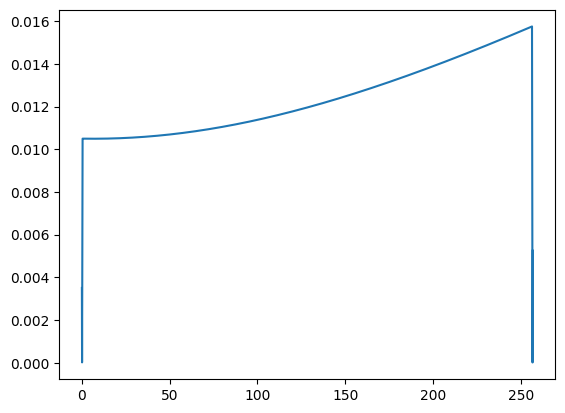

In [56]:
imany=[1,2,3,4]
vals=combine_ar_multi(imany,f810dict)
plt.plot(vals[0],vals[1])

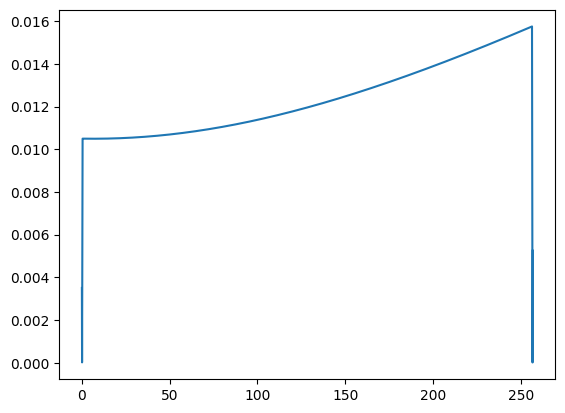

In [57]:
value = combine_ar(1,2,f810dict)
value2 = combine_ar(3,4,f810dict)
x=np.concatenate((value[0], value2[0]))
y=np.concatenate((value[1], value2[1]))
plt.plot(x, y)

Text(0.5, 0, 'Path Length (m)')

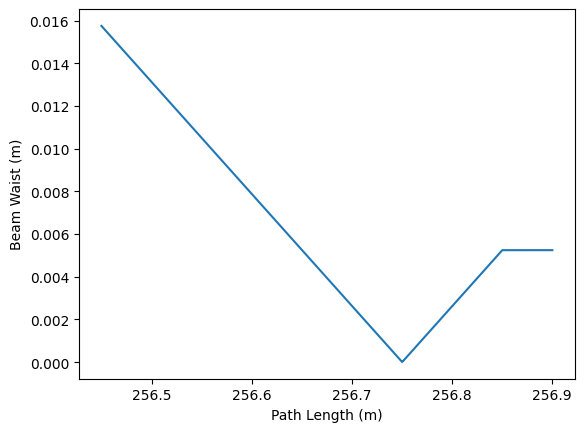

In [58]:
plt.plot(value2[0], value2[1])
plt.ylabel('Beam Waist (m)')
plt.xlabel('Path Length (m)')